In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, 
                             classification_report, ConfusionMatrixDisplay,
                             f1_score, recall_score)

In [2]:
df = pd.read_csv("spam.csv", encoding = "latin-1")
df = df[["v1", "v2"]].copy()
df.columns = ["label", "message"]
df = df.dropna(subset = ["label", "message"])
df["label"] = df["label"].str.strip().str.lower()

print("Shape of dataset:", df.shape)
print("Labels:", df["label"].unique())
print("Missing Values:\n", df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())

df.head()

Shape of dataset: (5572, 2)
Labels: ['ham' 'spam']
Missing Values:
 label      0
message    0
dtype: int64
Duplicate rows: 403


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


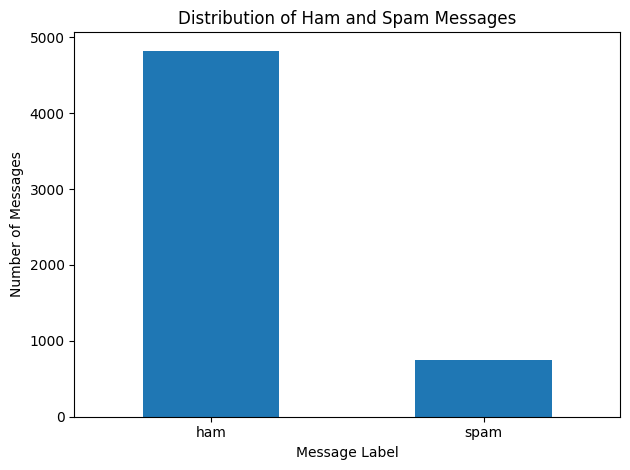

In [3]:
df["label"].value_counts().reindex(["ham", "spam"]).plot(kind = "bar")
plt.title("Distribution of Ham and Spam Messages")
plt.xlabel("Message Label")
plt.ylabel("Number of Messages")
plt.xticks(rotation = 0)
plt.tight_layout()
plt.show()

In [4]:
X = df["message"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, 
                                                    random_state = 42, stratify = y)

print("Training messages:", len(X_train))
print("Testing messages:", len(X_test))

Training messages: 4457
Testing messages: 1115


In [5]:
model = Pipeline([
    ("tfidf", TfidfVectorizer(stop_words = "english")), ("classifer",
                                                         LogisticRegression(max_iter = 1000))
])

model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('classifer', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['ham','spam']"
,"stop_words stop_words: {'english'}, list, default=NoneIf a string, it is passed to _check_stop_list and the appropriate stoplist is returned. 'english' is currently the only supported stringvalue.There are several known issues with 'english' and you shouldconsider an alternative (see :ref:`stop_words`).If a list, that list is assumed to contain stop words, all of whichwill be removed from the resulting tokens.Only applies if ``analyzer == 'word'``.If None, no stop words will be used. In this case, setting `max_df`to a higher value, such as in the range (0.7, 1.0), can automatically detectand filter stop words based on intra corpus document frequency of terms.",'english'
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is p

In [9]:
predictions = model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, predictions), 4))
print("Precision (spam):", round(precision_score(y_test, predictions, pos_label = "spam"), 4))
print("Recall (spam):", round(recall_score(y_test, predictions, pos_label = "spam"), 4))
print("F1-score:", round(f1_score(y_test, predictions, pos_label = "spam"), 4))

print("\nClassification Report:")
print(classification_report(y_test, predictions))

Accuracy: 0.9677
Precision (spam): 1.0
Recall (spam): 0.7584
F1-score: 0.8626

Classification Report:
              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       966
        spam       1.00      0.76      0.86       149

    accuracy                           0.97      1115
   macro avg       0.98      0.88      0.92      1115
weighted avg       0.97      0.97      0.97      1115



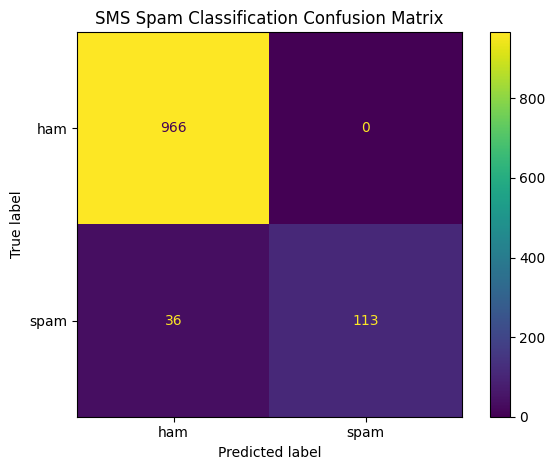

In [7]:
ConfusionMatrixDisplay.from_predictions(
    y_test, predictions, labels = ["ham", "spam"], values_format = "d")

plt.title("SMS Spam Classification Confusion Matrix")
plt.tight_layout()
plt.show()

In [8]:
probabilities = model.predict_proba(X_test)
classes = list(model.named_steps["classifer"].classes_)

results = pd.DataFrame(
    {"message" : X_test,
     "actual" : y_test,
     "predicted" : predictions}
)

results["confidence"] = [
    probabilities[i, classes.index(predictions[i])]
    for i in range(len(predictions))
]

errors = results[results["actual"] != results["predicted"]]
print("Number of misclassified text messages:", len(errors))

five_errors = errors.sort_values("confidence", ascending = False).head(5)
pd.set_option("display.max_colwidth", 200)
five_errors[["message", "actual", "predicted", "confidence"]]

Number of misclassified text messages: 36


,message,actual,predicted,confidence
3358,Sorry I missed your call let's talk when you have the time. I'm on 07090201529,spam,ham,0.975403
750,"Do you realize that in about 40 years, we'll have thousands of old ladies running around with tattoos?",spam,ham,0.938821
1429,For sale - arsenal dartboard. Good condition but no doubles or trebles!,spam,ham,0.917751
730,Email AlertFrom: Jeri StewartSize: 2KBSubject: Low-cost prescripiton drvgsTo listen to email call 123,spam,ham,0.908366
3979,ringtoneking 84484,spam,ham,0.904967
